# Блокнот 04: Просторово-часові зв'язки та маршрути загроз (RQ3)

**Дослідницьке питання (RQ3):**
> *Чи можна на основі взаємних часових затримок (lead-lag cross-correlation) між безпосередньо суміжними областями відновити типові просторово-часові ланцюжки поширення тривог («хвилі» підльоту), ізолювавши при цьому синхронні загальнонаціональні тривоги?*

У цьому блокноті досліджено:
1. Побудову графа фізичного сухопутного сусідства (49 пар суміжних областей України).
2. Дискретизацію часового ряду в **2-хвилинну бінарну сітку імпульсів стартів тривог** (`time_step_min = 2` хв, вікно імпульсу старту `onset_window_min = 10` хв / `5` кроків; `1,177,381` кроків на Official та `1,201,676` кроків на Volunteer з 2022 по 2026 рік).
3. Ізоляцію синхронних загальнонаціональних тривог (`>= 15` областей одночасно, наприклад зльоти МіГ-31К).
4. Розрахунок крос-кореляції імпульсів стартів із лагами $\tau \in [-180, +180]$ хв (крок 2 хв), оцінку асиметрії плечей (`shoulder_diff = pos_shoulder - neg_shoulder` на вікнах `+2..+60` хв проти `-60..-2` хв) та визначення `peak_nonzero_lag_min` і `lead_time_min`.
5. Побудову орієнтованого графа затримок для обох незалежних джерел (`Official` та `Volunteer`).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

summary_path = Path("../reports/official/spatial_lead_lag_summary.csv")
vol_summary_path = Path("../reports/volunteer/spatial_lead_lag_summary.csv")
routes_df = pd.read_csv(summary_path)
vol_routes_df = pd.read_csv(vol_summary_path)
print(f"Завантажено результати аналізу для {len(routes_df)} пар суміжних областей (Official та Volunteer).")
print("=== OFFICIAL: Топ-10 пар суміжних областей ===")
display(routes_df.head(10))
print("\n=== VOLUNTEER: Топ-10 пар суміжних областей ===")
display(vol_routes_df.head(10))

Завантажено результати аналізу для 49 пар суміжних областей (Official та Volunteer).
=== OFFICIAL: Топ-10 пар суміжних областей ===


,region_a,region_b,dominant_pair,direction_type,lead_time_min,best_lag_min,peak_nonzero_lag_min,shoulder_diff,max_correlation,correlation_lag0,joint_active_intervals,joint_onset_steps
0,Херсонська область,Миколаївська область,Херсонська область ➔ Миколаївська область,Спрямоване випередження (A ➔ B),8,0,8,0.004643,0.4940,0.4940,107845,12048
1,Черкаська область,Кіровоградська область,Кіровоградська область ➔ Черкаська область,Спрямоване випередження (B ➔ A),12,0,-12,-0.003794,0.4682,0.4682,65134,7939
2,Дніпропетровська область,Запорізька область,Дніпропетровська область ⟷ Запорізька область,Синхронне включення (< 2 хв),0,0,0,-0.000769,0.4237,0.4237,286285,13744
3,Київська область,м. Київ,Київська область ➔ м. Київ,Спрямоване випередження (A ➔ B),18,-2,18,0.007795,0.3309,0.3257,45630,3286
4,Полтавська область,Дніпропетровська область,Дніпропетровська область ➔ Полтавська область,Спрямоване випередження (B ➔ A),8,0,-8,-0.003612,0.3277,0.3277,167724,8944
5,Волинська область,Рівненська область,Рівненська область ➔ Волинська область,Спрямоване випередження (B ➔ A),36,0,-36,-0.011596,0.3195,0.3195,5641,446
6,Львівська область,Івано-Франківська область,Львівська область ➔ Івано-Франківська область,Спрямоване випередження (A ➔ B),22,0,22,0.003373,0.3175,0.3175,2323,177
7,Закарпатська область,Івано-Франківська область,Івано-Франківська область ➔ Закарпатська область,Спрямоване випередження (B ➔ A),6,0,-6,-0.006668,0.3141,0.3141,1071,100
8,Полтавська область,Черкаська область,Полтавська область ➔ Черкаська область,Спрямоване випередження (A ➔ B),8,0,8,0.008177,0.2806,0.2806,70204,5660
9,Полтавська область,Кіровоградська область,Полтавська область ➔ Кіровоградська область,Спрямоване випередження (A ➔ B),8,0,8,0.004587,0.2763,0.2763,89225,6767



=== VOLUNTEER: Топ-10 пар суміжних областей ===


,region_a,region_b,dominant_pair,direction_type,lead_time_min,best_lag_min,peak_nonzero_lag_min,shoulder_diff,max_correlation,correlation_lag0,joint_active_intervals,joint_onset_steps
0,Полтавська область,Кіровоградська область,Полтавська область ➔ Кіровоградська область,Спрямоване випередження (A ➔ B),6,0,6,0.001263,0.4292,0.4292,78239,13077
1,Закарпатська область,Івано-Франківська область,Івано-Франківська область ➔ Закарпатська область,Спрямоване випередження (B ➔ A),4,0,-4,-0.002040,0.4136,0.4136,2694,370
2,Черкаська область,Кіровоградська область,Кіровоградська область ➔ Черкаська область,Спрямоване випередження (B ➔ A),12,0,-12,-0.004629,0.3637,0.3637,54379,8186
3,Київська область,м. Київ,м. Київ ➔ Київська область,Спрямоване випередження (B ➔ A),2,-2,-2,-0.009044,0.3026,0.2956,26779,4256
4,Тернопільська область,Івано-Франківська область,Тернопільська область ➔ Івано-Франківська область,Спрямоване випередження (A ➔ B),24,0,24,0.005842,0.2723,0.2723,4356,381
5,Полтавська область,Черкаська область,Полтавська область ➔ Черкаська область,Спрямоване випередження (A ➔ B),10,0,10,0.002954,0.2656,0.2656,45051,6218
6,Івано-Франківська область,Чернівецька область,Чернівецька область ➔ Івано-Франківська область,Спрямоване випередження (B ➔ A),42,0,-42,-0.006702,0.2627,0.2627,4037,338
7,Київська область,Чернігівська область,Чернігівська область ➔ Київська область,Спрямоване випередження (B ➔ A),6,0,-6,-0.001554,0.2533,0.2533,41901,5752
8,Херсонська область,Миколаївська область,Миколаївська область ➔ Херсонська область,Спрямоване випередження (B ➔ A),152,0,-152,-0.001859,0.2500,0.2500,66564,8899
9,Житомирська область,Вінницька область,Вінницька область ➔ Житомирська область,Спрямоване випередження (B ➔ A),16,0,-16,-0.005239,0.2368,0.2368,18045,1859


## 1. Візуалізація топ ланцюжків поширення тривог (Lead-Lag Аналіз)

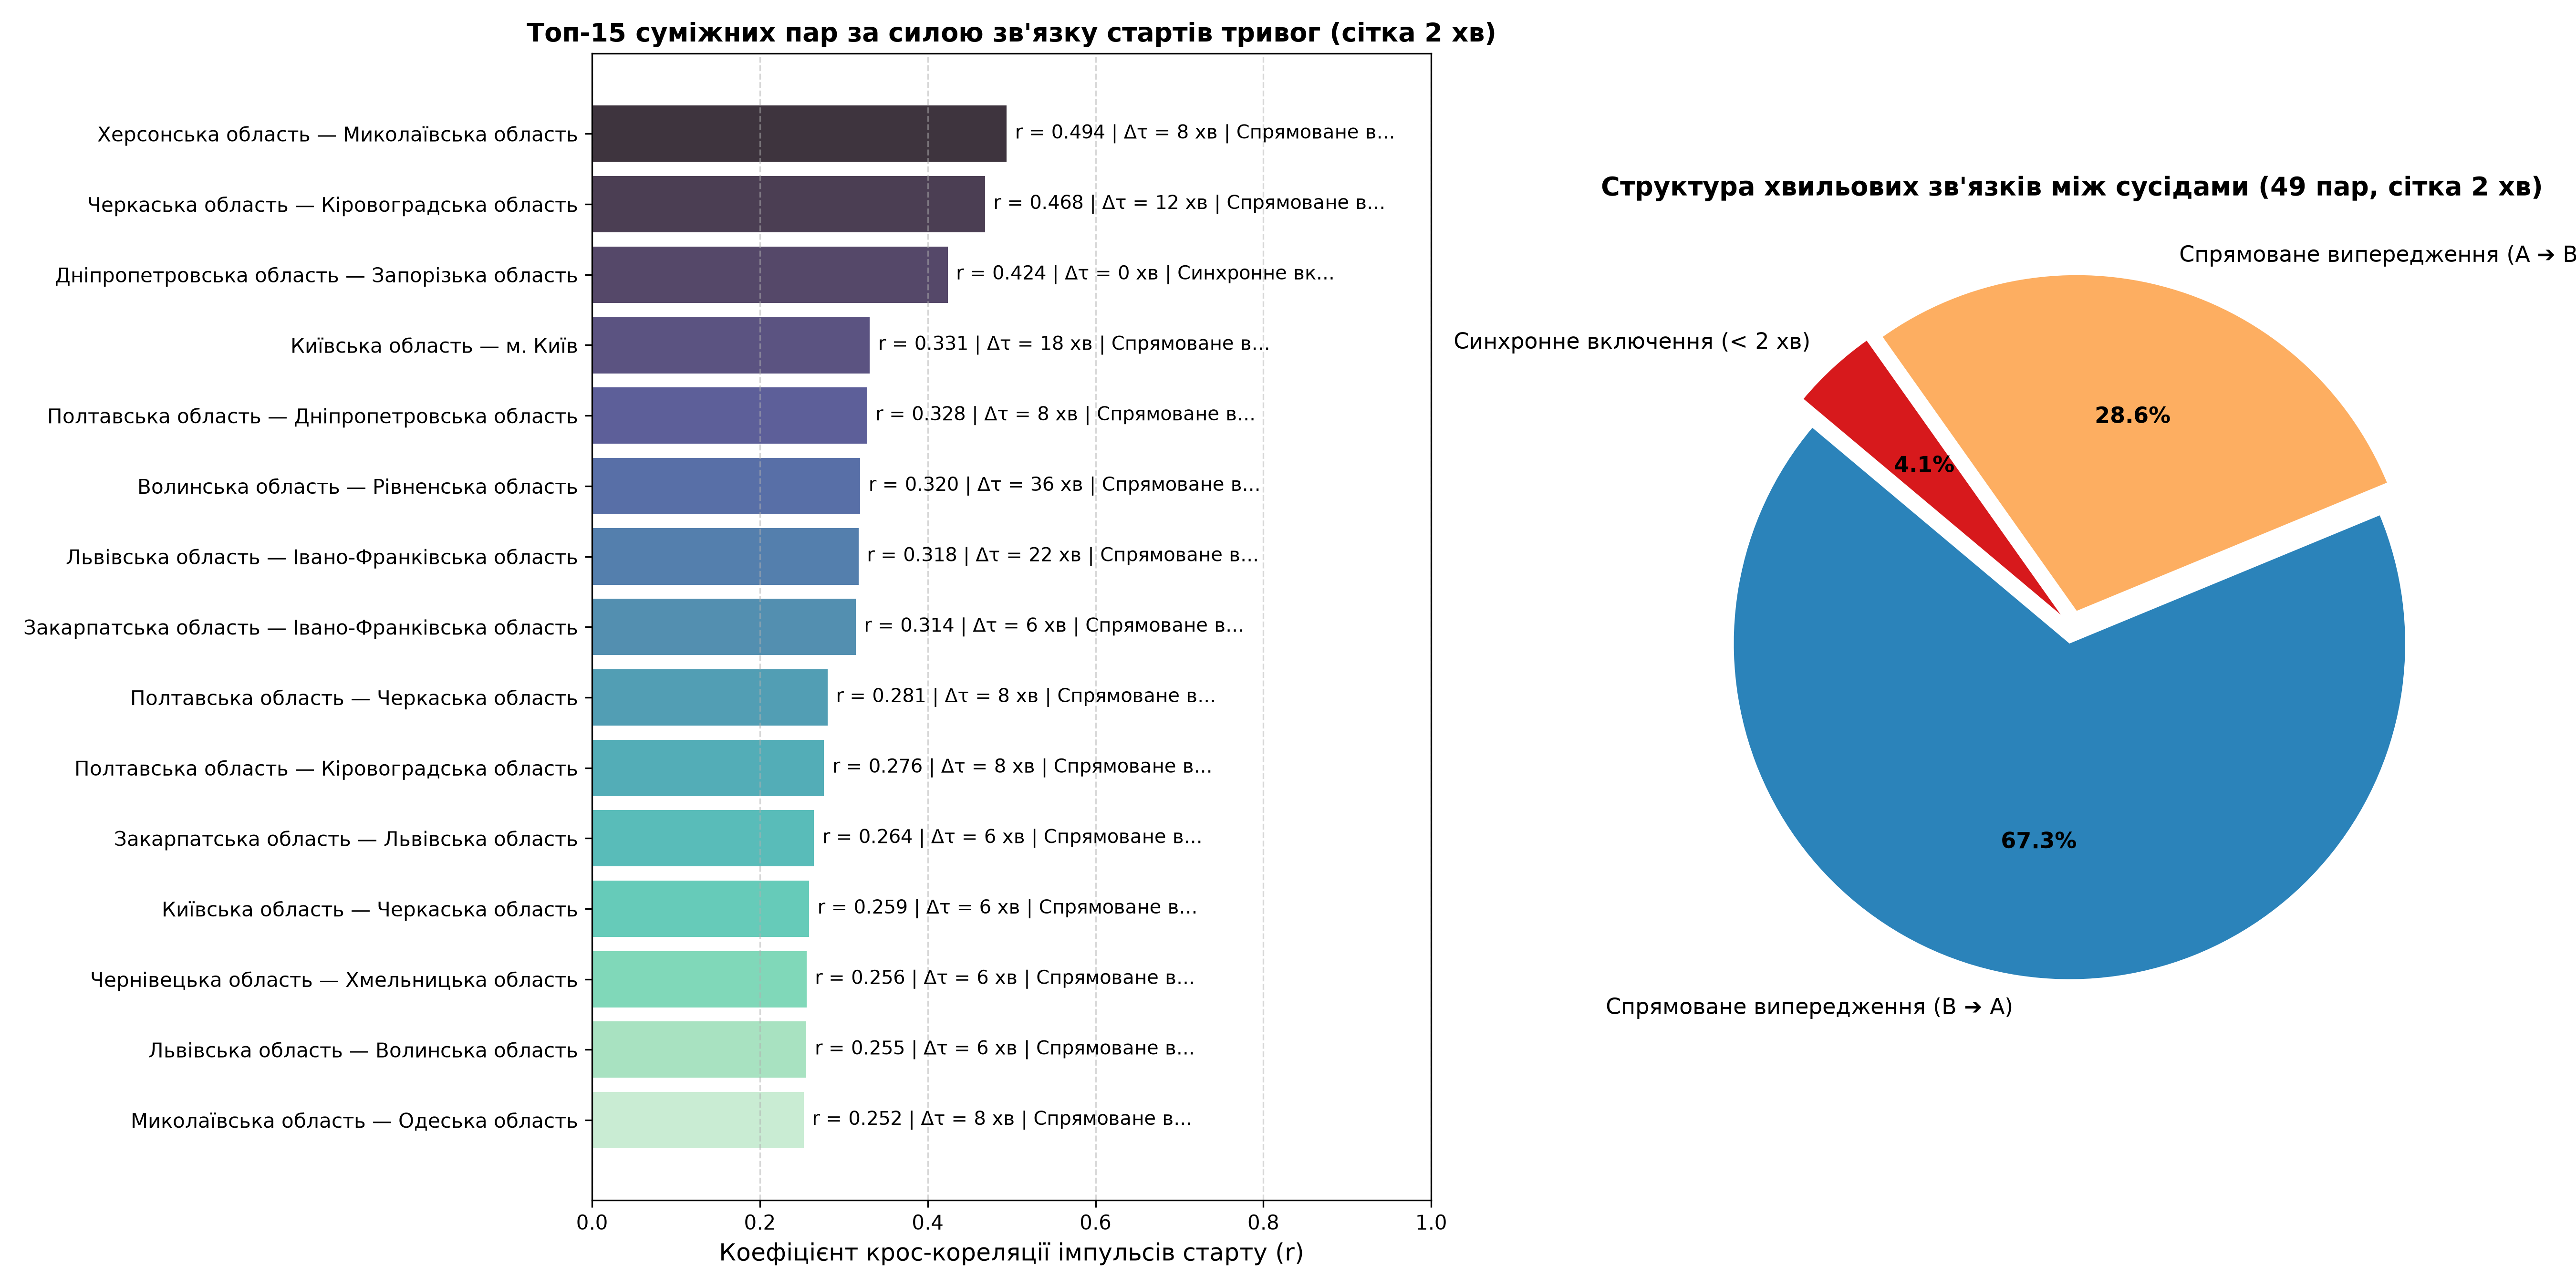

In [2]:
display(Image("../reports/official/figures/06_spatial_cross_correlation_routes.png"))

## 2. Найсильніші кореляції між сусідніми областями

In [3]:
print("Топ-15 найсильніших пар за рівнем кореляції (Official):")
display(routes_df.sort_values("max_correlation", ascending=False).head(15))

Топ-15 найсильніших пар за рівнем кореляції (Official):


,region_a,region_b,dominant_pair,direction_type,lead_time_min,best_lag_min,peak_nonzero_lag_min,shoulder_diff,max_correlation,correlation_lag0,joint_active_intervals,joint_onset_steps
0,Херсонська область,Миколаївська область,Херсонська область ➔ Миколаївська область,Спрямоване випередження (A ➔ B),8,0,8,0.004643,0.4940,0.4940,107845,12048
1,Черкаська область,Кіровоградська область,Кіровоградська область ➔ Черкаська область,Спрямоване випередження (B ➔ A),12,0,-12,-0.003794,0.4682,0.4682,65134,7939
2,Дніпропетровська область,Запорізька область,Дніпропетровська область ⟷ Запорізька область,Синхронне включення (< 2 хв),0,0,0,-0.000769,0.4237,0.4237,286285,13744
3,Київська область,м. Київ,Київська область ➔ м. Київ,Спрямоване випередження (A ➔ B),18,-2,18,0.007795,0.3309,0.3257,45630,3286
4,Полтавська область,Дніпропетровська область,Дніпропетровська область ➔ Полтавська область,Спрямоване випередження (B ➔ A),8,0,-8,-0.003612,0.3277,0.3277,167724,8944
5,Волинська область,Рівненська область,Рівненська область ➔ Волинська область,Спрямоване випередження (B ➔ A),36,0,-36,-0.011596,0.3195,0.3195,5641,446
6,Львівська область,Івано-Франківська область,Львівська область ➔ Івано-Франківська область,Спрямоване випередження (A ➔ B),22,0,22,0.003373,0.3175,0.3175,2323,177
7,Закарпатська область,Івано-Франківська область,Івано-Франківська область ➔ Закарпатська область,Спрямоване випередження (B ➔ A),6,0,-6,-0.006668,0.3141,0.3141,1071,100
8,Полтавська область,Черкаська область,Полтавська область ➔ Черкаська область,Спрямоване випередження (A ➔ B),8,0,8,0.008177,0.2806,0.2806,70204,5660
9,Полтавська область,Кіровоградська область,Полтавська область ➔ Кіровоградська область,Спрямоване випередження (A ➔ B),8,0,8,0.004587,0.2763,0.2763,89225,6767


## 3. Важливе методологічне розмежування

> **Застереження:** Даний граф відображає **статистичну послідовність оголошення офіційних сповіщень**, а не фізичну радіолокаційну траєкторію повітряного судна чи ракети. Розрахований Lead Time показує середню затримку увімкнення сирени між сусідніми областями при проходженні локальних хвиль загроз.